In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / "pkg_utilities").is_dir():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from pkg_utilities.graph_plotting_functions import plot_single, plot_secondary, plot_numeric_feature

In [4]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    average_precision_score
)

# Data Overview

In [5]:
quant_data = pd.read_csv("../data/Quant_Challenge_data_amended.csv", index_col=0)

In [6]:
quant_data.head()

,income,loan_amount,term_length,install_to_inc,occup,marital,schufa,num_applic,OBS_DATE,target_var
0,18785.517943694504,12300,67.0,0.009772532761805456,NaN,Single,7106.014471346445,1,18JUL2018 - 00:00:00,NaN
1,12861.495159877606,Not avail.,113.0,0.003509136597401741,Employee,Divorced,7694.806893720367,1,16JUL2018 - 00:00:00,0
2,14886.776341632107,10700,Not avail.,0.013310346283231944,Worker,Single,7142.496337537019,1,21DEC2010 - 00:00:00,1
3,Not avail.,33000,112.0,0.004760874885112928,Employee,Single,7446.1706118576485,1,05NOV2015 - 00:00:00,0
4,15897.753806874589,19900,59.0,0.02121608748572823,Worker,Separated,7241.656646188094,1,13JUL2015 - 00:00:00,1


In [7]:
#target_var value counts
quant_data["target_var"].value_counts(dropna=False)

target_var
0             7982
1             1454
Not avail.     296
NaN            268
Name: count, dtype: int64

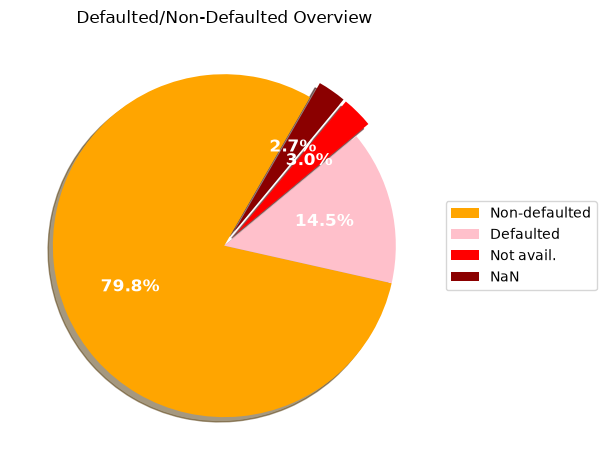

In [8]:
# plt.pie(
#     quant_data["target_var"].value_counts(),
#     labels=["Non-defaulted", "Defaulted", "Not avail."],
#     autopct="%1.1f%%",
#     startangle=90
# )
explode = (0, 0, 0.1, 0.1)  # only "explode" the 2nd slice (i.e. 'Hogs')

fig, ax = plt.subplots()
pie=ax.pie(quant_data["target_var"].value_counts(dropna=False), explode=explode, #labels=["Non-defaulted", "Defaulted", "Not avail."], 
       colors = ["orange", "pink", "red", "darkred"],
       shadow=True, startangle=60)
# plt.show()
# wedges, _, _ = plt.pie(
#     quant_data["target_var"].value_counts(),
#     colors = ["orange", "pink", "red"],
#     autopct="%1.1f%%",
#     startangle=60
# )
ax.pie_label(pie, '{frac:.1%}', textprops=dict(color="w", size=12, weight="bold"))
plt.legend(["Non-defaulted", "Defaulted", "Not avail.", "NaN"], loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("Defaulted/Non-Defaulted Overview")
plt.tight_layout()
plt.show()

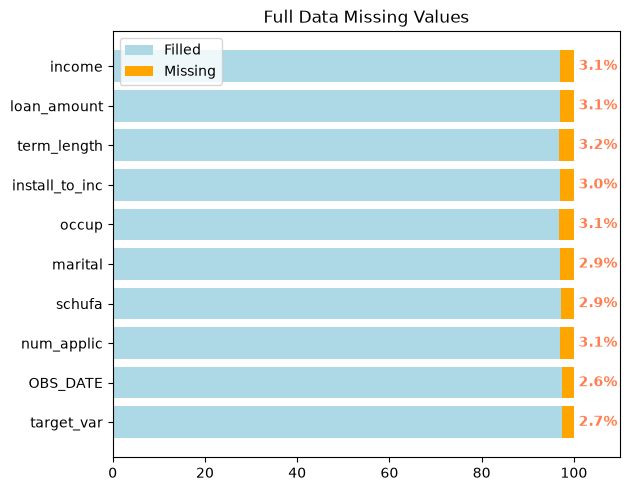

In [9]:
filled = (quant_data.notna().sum()/ len(quant_data)) * 100
missing = (quant_data.isna().sum()/ len(quant_data)) * 100
plt.barh(quant_data.columns, filled, color='lightblue', label='Filled')
# plt.barh(quant_data.columns, missing, left=filled, color='orange', label='Missing')

# plt.legend(loc='best')
# plt.show()
bars_missing = plt.barh(quant_data.columns, missing, left=filled, color='orange', label='Missing')

# 2. Loop and print the exact missing value if it is greater than 0
for bar in bars_missing:
    width = bar.get_width()
    if width > 0:
        # Places a precise label slightly to the right of the tiny sliver
        plt.text(bar.get_x() + width + 1, bar.get_y() + bar.get_height()/2, 
                 f'{width:.1f}%', va='center', ha='left', color='coral', fontweight='bold')
plt.gca().invert_yaxis() 
plt.xlim(0, 110) # Give room on the right for text labels
plt.legend()
plt.tight_layout()
plt.title("Full Data Missing Values")
plt.show()

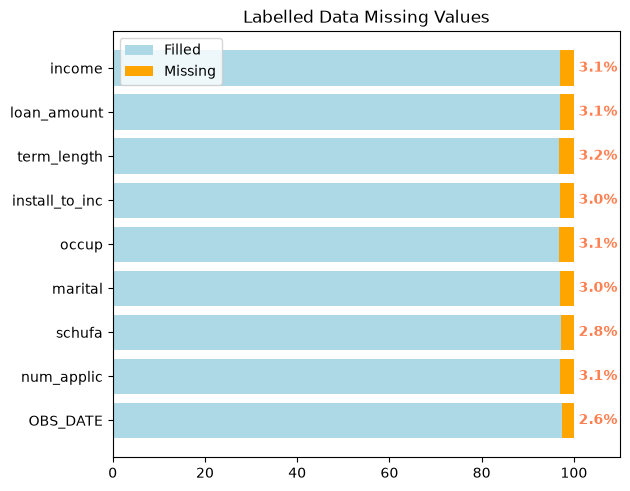

In [10]:
#nulls after we remove unlabelled rows
labelled_df = quant_data[quant_data['target_var']!="Not avail."].iloc[:, :-1].copy()

filled = (labelled_df.notna().sum()/ len(labelled_df)) * 100
missing = (labelled_df.isna().sum()/ len(labelled_df)) * 100
plt.barh(labelled_df.columns, filled, color='lightblue', label='Filled')
# plt.barh(quant_data.columns, missing, left=filled, color='orange', label='Missing')

# plt.legend(loc='best')
# plt.show()
bars_missing = plt.barh(labelled_df.columns, missing, left=filled, color='orange', label='Missing')

# 2. Loop and print the exact missing value if it is greater than 0
for bar in bars_missing:
    width = bar.get_width()
    if width > 0:
        # Places a precise label slightly to the right of the tiny sliver
        plt.text(bar.get_x() + width + 1, bar.get_y() + bar.get_height()/2, 
                 f'{width:.1f}%', va='center', ha='left', color='coral', fontweight='bold')
plt.gca().invert_yaxis() 
plt.xlim(0, 110) # Give room on the right for text labels
plt.legend()
plt.tight_layout()
plt.title("Labelled Data Missing Values")
plt.show()

In [11]:
labelled_df = quant_data.loc[
    quant_data["target_var"].notna()
    & quant_data["target_var"].ne("Not avail.")
]

In [12]:
labelled_df=labelled_df.replace("Not avail.", pd.NA)
labelled_df["target_var"] = pd.to_numeric(
    labelled_df["target_var"],
    errors="coerce"
)
labelled_df["OBS_DATE"] = pd.to_datetime(
    labelled_df["OBS_DATE"],
    format="%d%b%Y - %H:%M:%S",
    errors="coerce"
)

# Wrong Entries (numerical occup)

In [13]:
def text_only(values, errors="coerce"):
    is_numeric = pd.to_numeric(values, errors=errors).notna()
    return values.where(~is_numeric)


parsers = {
    "income": pd.to_numeric,
    "loan_amount": pd.to_numeric,
    "term_length": pd.to_numeric,
    "install_to_inc": pd.to_numeric,
    "occup": text_only,
    "marital": text_only,
    "schufa": pd.to_numeric,
    "num_applic": pd.to_numeric,
    "OBS_DATE": pd.to_datetime
}

stats = {}
failed_values = {}

for column, parser in parsers.items():
    values = labelled_df[column].replace(r"^\s*$", pd.NA, regex=True)
    values = values.replace("Not avail.", pd.NA)
    parsed = parser(values, errors="coerce")

    failed = values.notna() & parsed.isna()

    stats[column] = {
        "failed_count": failed.sum(),
        "failed_pct": failed.sum() / len(values) * 100
    }

    failed_values[column] = values[failed].value_counts()

parse_stats = pd.DataFrame.from_dict(stats, orient="index")
parse_stats

,failed_count,failed_pct
income,0,0.000000
loan_amount,0,0.000000
term_length,0,0.000000
install_to_inc,0,0.000000
occup,267,2.829589
marital,0,0.000000
schufa,0,0.000000
num_applic,0,0.000000
OBS_DATE,0,0.000000


# Null %

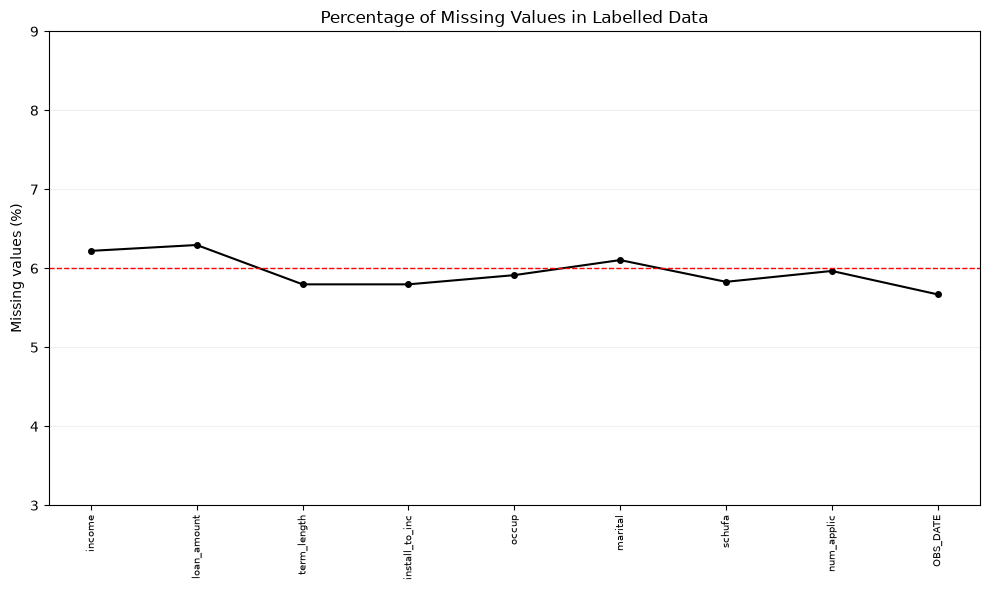

In [14]:
missing = labelled_df.drop(columns="target_var").isna().mean() * 100

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(missing.index, missing, color="black", marker="o", markersize=4)
ax.axhline(6, color="red", linestyle="--", linewidth=1)

ax.set(
    title="Percentage of Missing Values in Labelled Data",
    ylabel="Missing values (%)",
    ylim=(3, 9)
)

ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.grid(axis="y", alpha=0.2)
# plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

# Nulls/Errors Over Time

In [15]:
feature_cols = [
    "income",
    "loan_amount",
    "term_length",
    "install_to_inc",
    "occup",
    "marital",
    "schufa",
    "num_applic"
]

# Use cleaned data so invalid values already count as null
plot_data = labelled_df[["OBS_DATE", *feature_cols]].copy()

plot_data["OBS_DATE"] = pd.to_datetime(
    plot_data["OBS_DATE"],
    format="%d%b%Y - %H:%M:%S",
    errors="coerce"
)

plot_data = (
    plot_data
    .dropna(subset=["OBS_DATE"])
    .sort_values("OBS_DATE")
)

# Number of null cells in each row
plot_data["null_cells"] = (
    plot_data[feature_cols]
    .isna()
    .sum(axis=1)
)

monthly_nulls = (
    plot_data.set_index("OBS_DATE")
    .resample("MS")
    .agg(
        null_cells=("null_cells", "sum"),
        total_events=("null_cells", "size")
    )
)

monthly_nulls = monthly_nulls.loc[
    monthly_nulls["total_events"].gt(0)
].copy()

# Percentage of all possible feature cells that are null each month
monthly_nulls["null_cell_rate"] = (
    monthly_nulls["null_cells"]
    / (monthly_nulls["total_events"] * len(feature_cols))
)

# Each month's share of all null cells in the dataset
total_null_cells = monthly_nulls["null_cells"].sum()

monthly_nulls["monthly_null_pct"] = (
    monthly_nulls["null_cells"] / total_null_cells
)

monthly_nulls = monthly_nulls.reset_index()

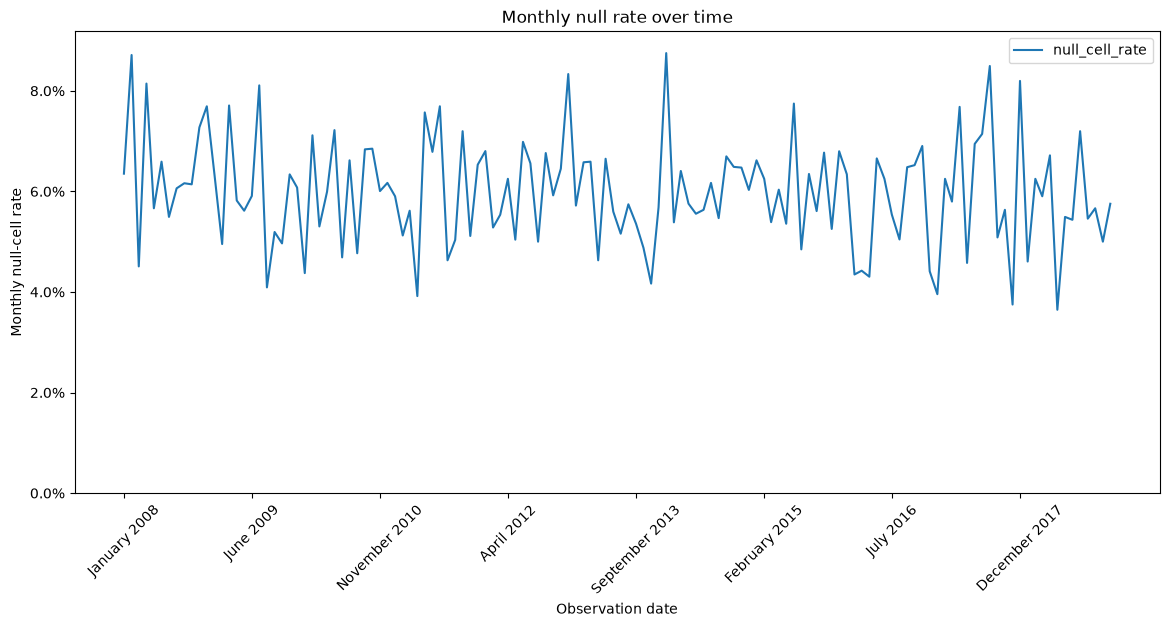

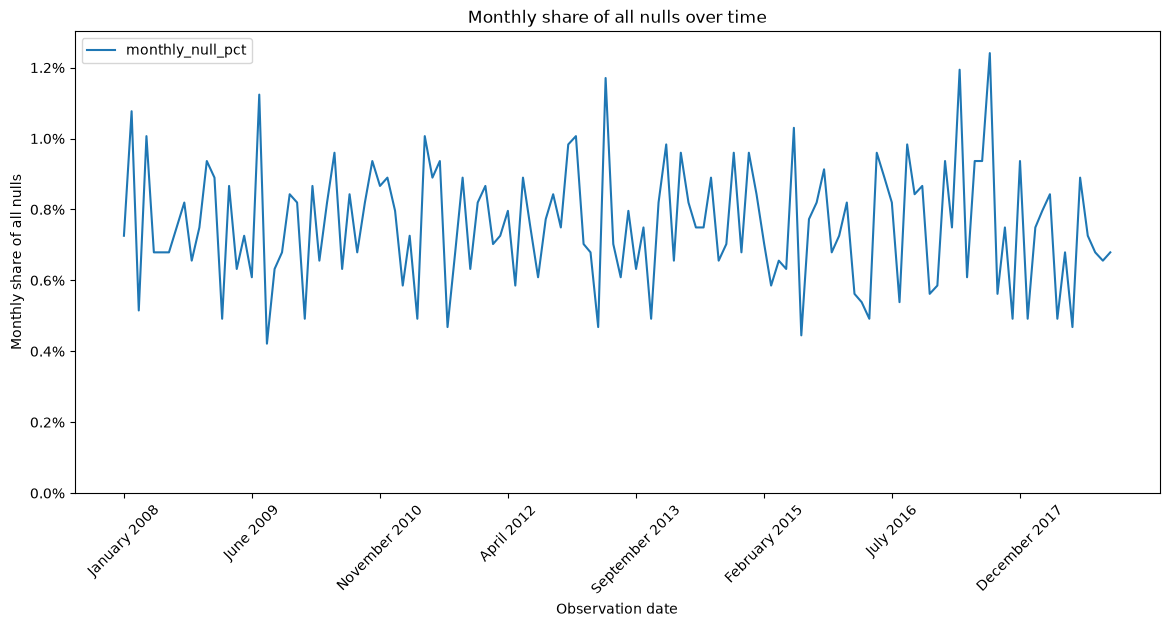

In [16]:
monthly_figure = plot_single(
    monthly_nulls,
    figsize=(14, 6),
    x_data="OBS_DATE",
    y_data="null_cell_rate",
    x_label="Observation date",
    y_label="Monthly null-cell rate",
    title="Monthly null rate over time",
    rotation=45,
    plot_type="line",
    y_lim=None
)

plt.show()
monthly_figure = plot_single(
    monthly_nulls,
    figsize=(14, 6),
    x_data="OBS_DATE",
    y_data="monthly_null_pct",
    x_label="Observation date",
    y_label="Monthly share of all nulls",
    title="Monthly share of all nulls over time",
    rotation=45,
    plot_type="line",
    y_lim=None
)

plt.show()

## remove null dates

Rows removed: 535
Rows remaining: 8901


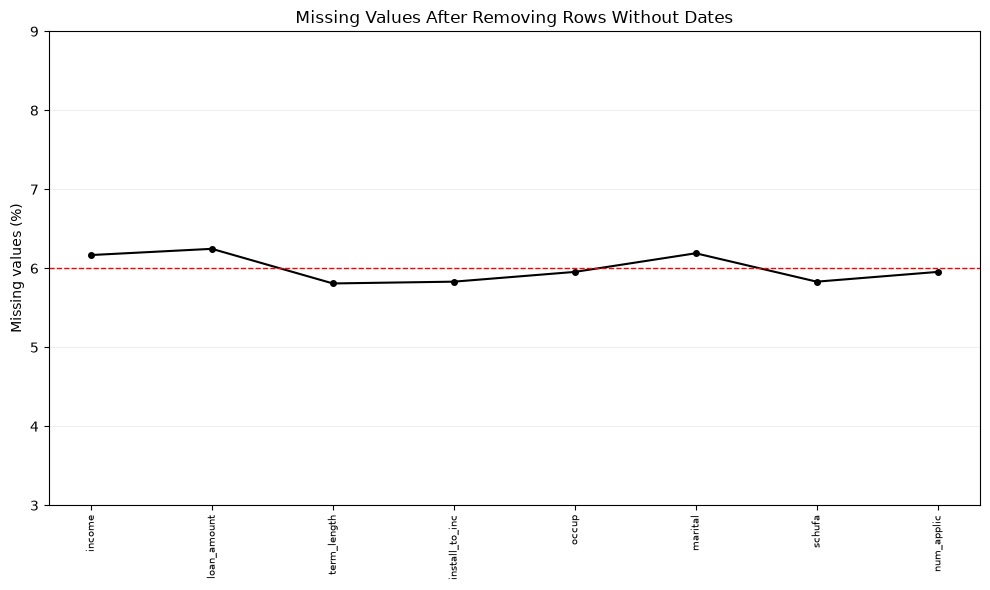

In [17]:
# Remove rows without a usable observation date
dated_df = labelled_df.dropna(subset=["OBS_DATE"]).copy()

print("Rows removed:", len(labelled_df) - len(dated_df))
print("Rows remaining:", len(dated_df))

# Exclude target, date and generated flags from this graph
feature_cols = [
    "income",
    "loan_amount",
    "term_length",
    "install_to_inc",
    "occup",
    "marital",
    "schufa",
    "num_applic"
]

missing = dated_df[feature_cols].isna().mean() * 100

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    missing.index,
    missing,
    color="black",
    marker="o",
    markersize=4
)

ax.axhline(6, color="red", linestyle="--", linewidth=1)

ax.set(
    title="Missing Values After Removing Rows Without Dates",
    ylabel="Missing values (%)",
    ylim=(3, 9)
)

ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

In [18]:
null_comparison = pd.DataFrame({
    "nulls_before": labelled_df[feature_cols].isna().sum(),
    "nulls_after": dated_df[feature_cols].isna().sum()
})

null_comparison["nulls_removed"] = (
    null_comparison["nulls_before"]
    - null_comparison["nulls_after"]
)

null_comparison["pct_before"] = (
    null_comparison["nulls_before"] / len(labelled_df) * 100
)

null_comparison["pct_after"] = (
    null_comparison["nulls_after"] / len(dated_df) * 100
)

null_comparison

,nulls_before,nulls_after,nulls_removed,pct_before,pct_after
income,587,549,38,6.220856,6.167846
loan_amount,594,556,38,6.295040,6.246489
term_length,547,517,30,5.796948,5.808336
install_to_inc,547,519,28,5.796948,5.830806
occup,558,530,28,5.913523,5.954387
marital,576,551,25,6.104281,6.190316
schufa,550,519,31,5.828741,5.830806
num_applic,563,530,33,5.966511,5.954387


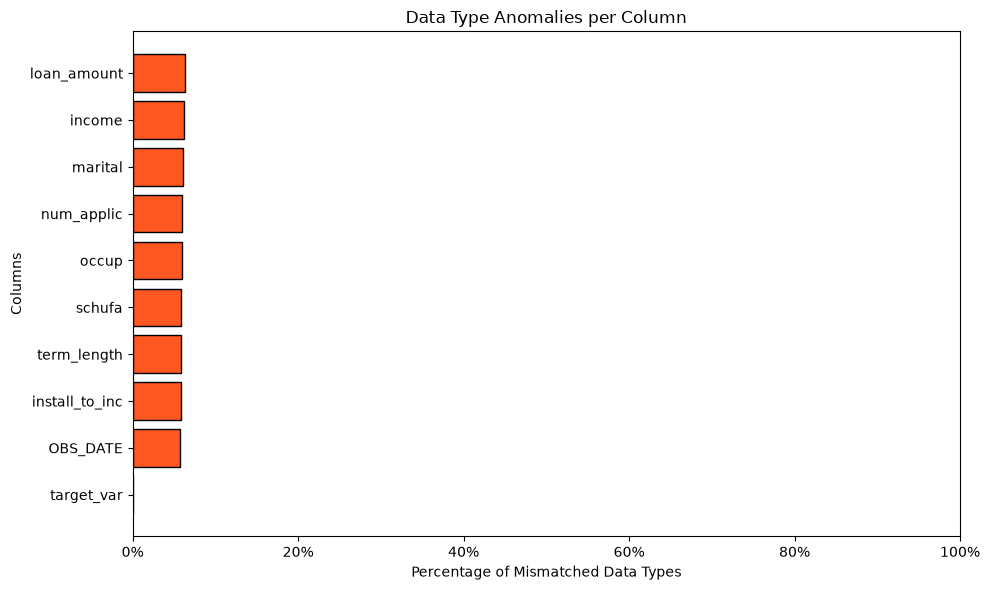

In [19]:
cell_types = labelled_df.map(type)
majority_types = cell_types.mode().iloc[0]

# 2. Count wrong types and convert directly to percentages
total_rows = len(labelled_df)
wrong_type_pct = (((cell_types != majority_types) & cell_types.notna()).sum() / total_rows) * 100

# 3. Sort so columns with the most type errors appear at the top
wrong_type_pct = wrong_type_pct.sort_values(ascending=False)
columns = wrong_type_pct.index

# 4. Plot using the bare matplotlib parameters
plt.figure(figsize=(10, 6))
plt.barh(columns, wrong_type_pct, color='#FF5722', edgecolor='black')

# 5. Format X-axis and invert Y-axis for top-to-bottom reading
plt.xlim(0, 100)
plt.gca().xaxis.set_major_formatter('{x:.0f}%')
plt.gca().invert_yaxis()

plt.xlabel('Percentage of Mismatched Data Types')
plt.ylabel('Columns')
plt.title('Data Type Anomalies per Column')
plt.tight_layout()
plt.show()

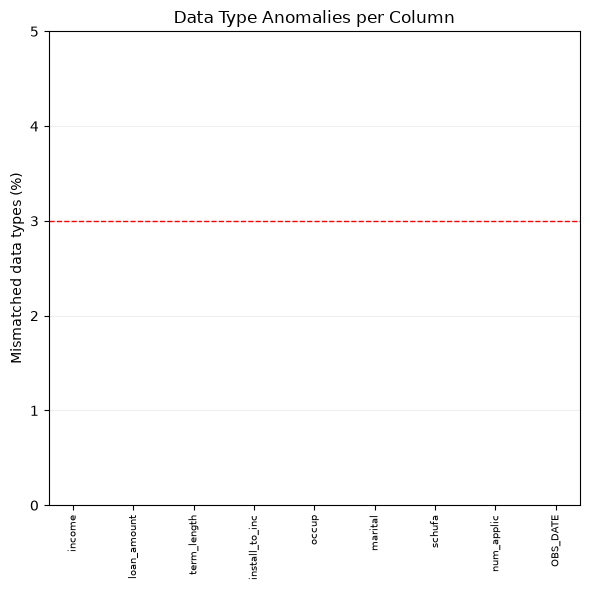

In [20]:
type_data = labelled_df.drop(columns="target_var")
cell_types = type_data.map(type)
majority_types = cell_types.mode().iloc[0]

total_rows = len(type_data)
wrong_type_pct = ((((cell_types != majority_types) & cell_types.notna()).sum() / total_rows) * 100)

fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(
    wrong_type_pct.index,
    wrong_type_pct,
    color="black",
    marker="o",
    markersize=4
)

ax.axhline(3, color="red", linestyle="--", linewidth=1)

ax.set(
    title="Data Type Anomalies per Column",
    ylabel="Mismatched data types (%)",
    ylim=(0, 5)
)

ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.grid(axis="y", alpha=0.2)
# plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

# Default Overview

## Monthly monitoring

The next cell plots the monthly default rate and the monthly share of defaults over time. The monthly rate is defaults divided by valid observations in that month; the monthly share is that month's defaults divided by all defaults in the dated months shown. Run the cell when you want to view the figures.

In [21]:


plot_data = quant_data[["OBS_DATE", "target_var"]].copy()
plot_data["OBS_DATE"] = pd.to_datetime(
    plot_data["OBS_DATE"], format="%d%b%Y - %H:%M:%S", errors="coerce"
)
plot_data["target_var"] = pd.to_numeric(
    plot_data["target_var"], errors="coerce"
)
plot_data = plot_data.loc[plot_data["target_var"].isin([0, 1])]
plot_data = plot_data.dropna(subset=["OBS_DATE"])
plot_data = plot_data.sort_values("OBS_DATE").reset_index(drop=True)

monthly_data = (
    plot_data.set_index("OBS_DATE")["target_var"]
    .resample("MS")
    .agg(defaults="sum", observations="count")
)
monthly_data = monthly_data.loc[monthly_data["observations"].gt(0)].copy()
total_defaults = monthly_data["defaults"].sum()
monthly_data["default_rate"] = (
    monthly_data["defaults"] / monthly_data["observations"]
)
monthly_data["monthly_default_pct"] = (
    monthly_data["defaults"] / total_defaults
)
monthly_data = monthly_data.reset_index().sort_values("OBS_DATE")

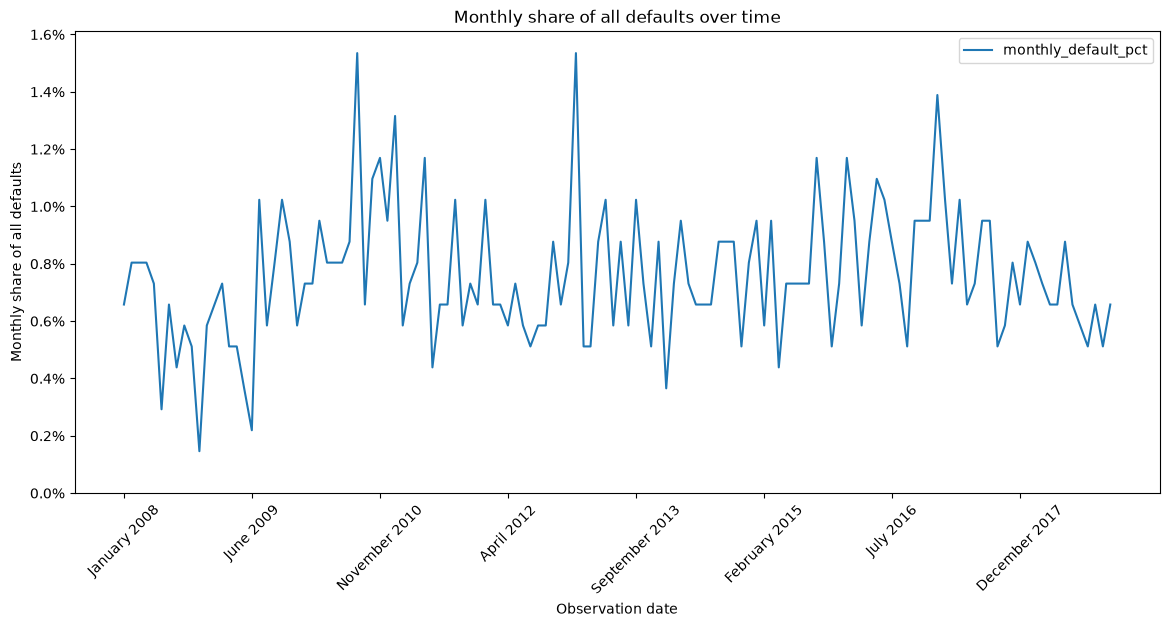

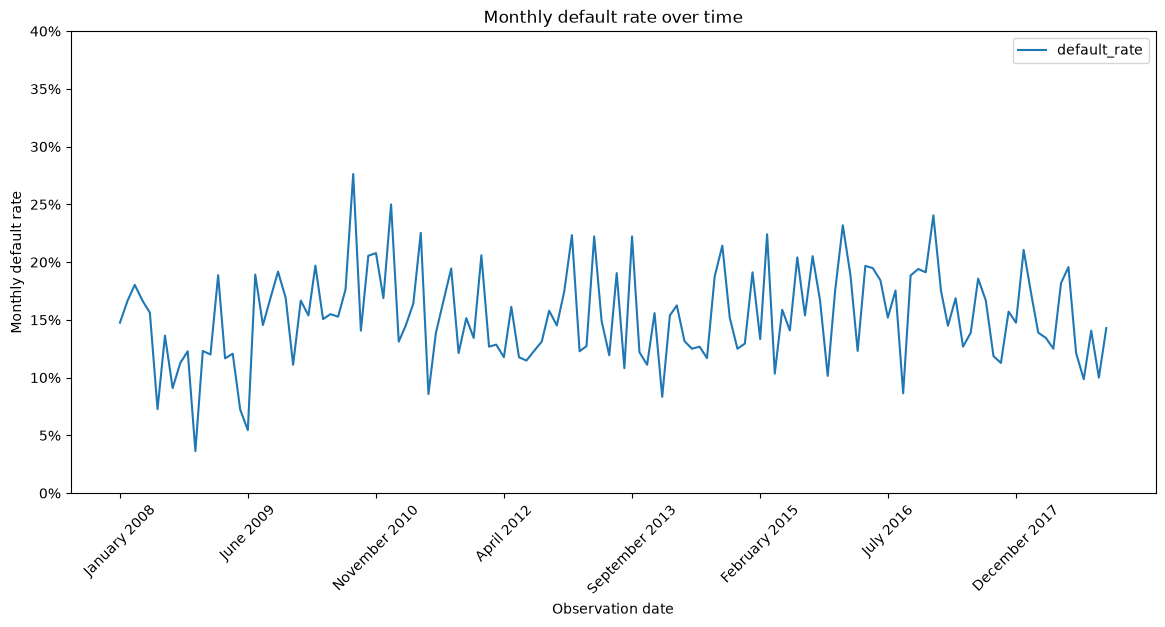

In [22]:


monthly_default_figure = plot_single(
    monthly_data,
    figsize=(14, 6),
    x_data="OBS_DATE",
    y_data="monthly_default_pct",
    x_label="Observation date",
    y_label="Monthly share of all defaults",
    title="Monthly share of all defaults over time",
    rotation=45,
    plot_type="line",
)
monthly_figure = plot_single(
    monthly_data,
    figsize=(14, 6),
    x_data="OBS_DATE",
    y_data="default_rate",
    x_label="Observation date",
    y_label="Monthly default rate",
    title="Monthly default rate over time",
    rotation=45,
    plot_type="line",
    y_lim=0.4,
)


## Monthly events with monthly default metrics

These secondary-axis charts show total dated records per month as light grey bars, alongside that period's default rate and share of all defaults.

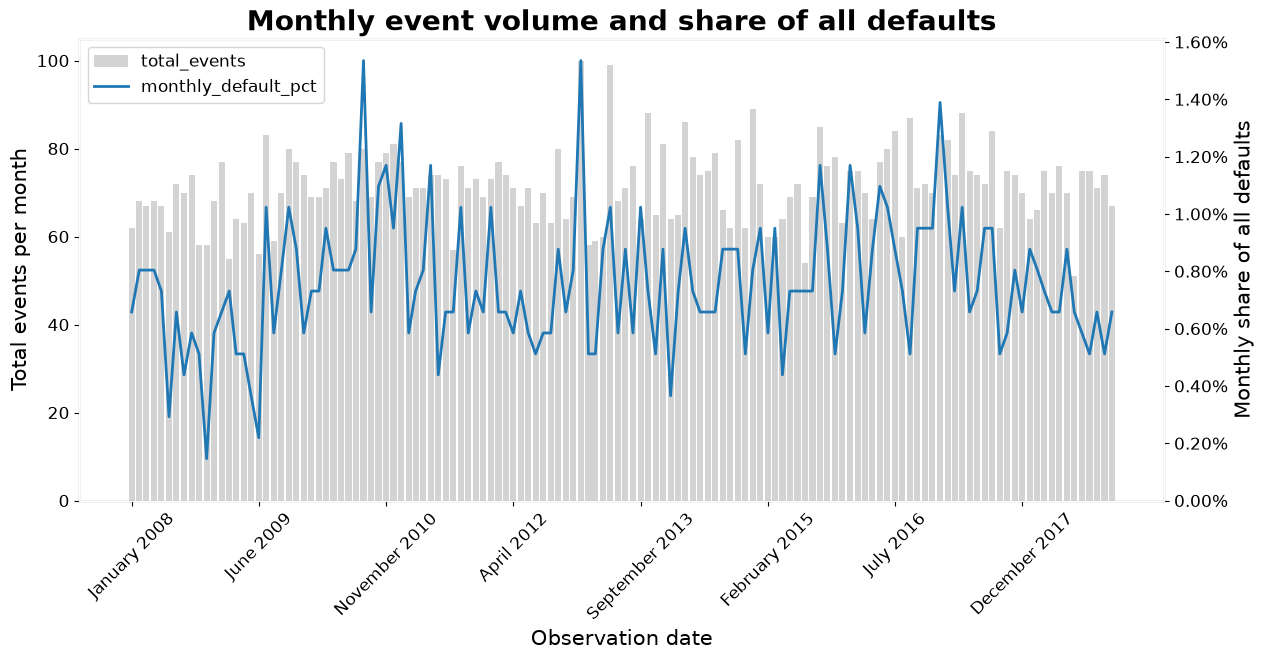

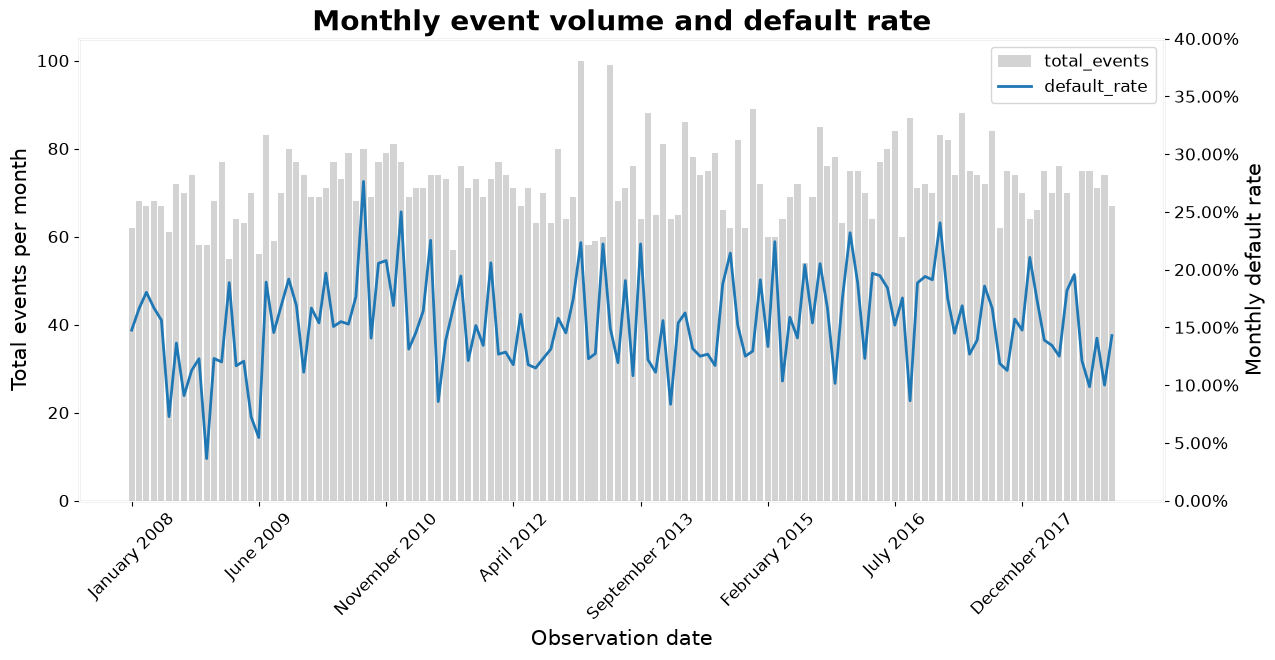

In [23]:
plot_source = quant_data[["OBS_DATE", "target_var"]].copy()
plot_source["OBS_DATE"] = pd.to_datetime(
    plot_source["OBS_DATE"], format="%d%b%Y - %H:%M:%S", errors="coerce"
)
plot_source["target_var"] = pd.to_numeric(
    plot_source["target_var"], errors="coerce"
)
dated_data = plot_source.dropna(subset=["OBS_DATE"])
valid_targets = dated_data.loc[dated_data["target_var"].isin([0, 1])]

monthly_events = (
    dated_data.set_index("OBS_DATE")
    .resample("MS")
    .size()
    .rename("total_events")
)
monthly_targets = (
    valid_targets.set_index("OBS_DATE")["target_var"]
    .resample("MS")
    .agg(defaults="sum", observations="count")
)
monthly_data = monthly_events.to_frame().join(monthly_targets, how="left")
monthly_data["default_rate"] = (
    monthly_data["defaults"] / monthly_data["observations"]
)
monthly_data["monthly_default_pct"] = (
    monthly_data["defaults"] / monthly_data["defaults"].sum()
)
monthly_data = monthly_data.reset_index().sort_values("OBS_DATE")

monthly_volume_default_share = plot_secondary(
    monthly_data,
    figsize=(14, 6),
    x_data="OBS_DATE",
    y1_data="total_events",
    y2_data="monthly_default_pct",
    x_label="Observation date",
    y1_label="Total events per month",
    y2_label="Monthly share of all defaults",
    title="Monthly event volume and share of all defaults",
    rotation=45,
    y1_lim=None,
    y2_lim=None,
)
monthly_volume_default_rate = plot_secondary(
    monthly_data,
    figsize=(14, 6),
    x_data="OBS_DATE",
    y1_data="total_events",
    y2_data="default_rate",
    x_label="Observation date",
    y1_label="Total events per month",
    y2_label="Monthly default rate",
    title="Monthly event volume and default rate",
    rotation=45,
    y1_lim=None,
    y2_lim=0.4,
)


## Weekly event totals with monthly default metrics

The bars show total dated records per Monday-to-Sunday week. The lines show monthly default rate and each month's share of all defaults, repeated for weeks in that month.

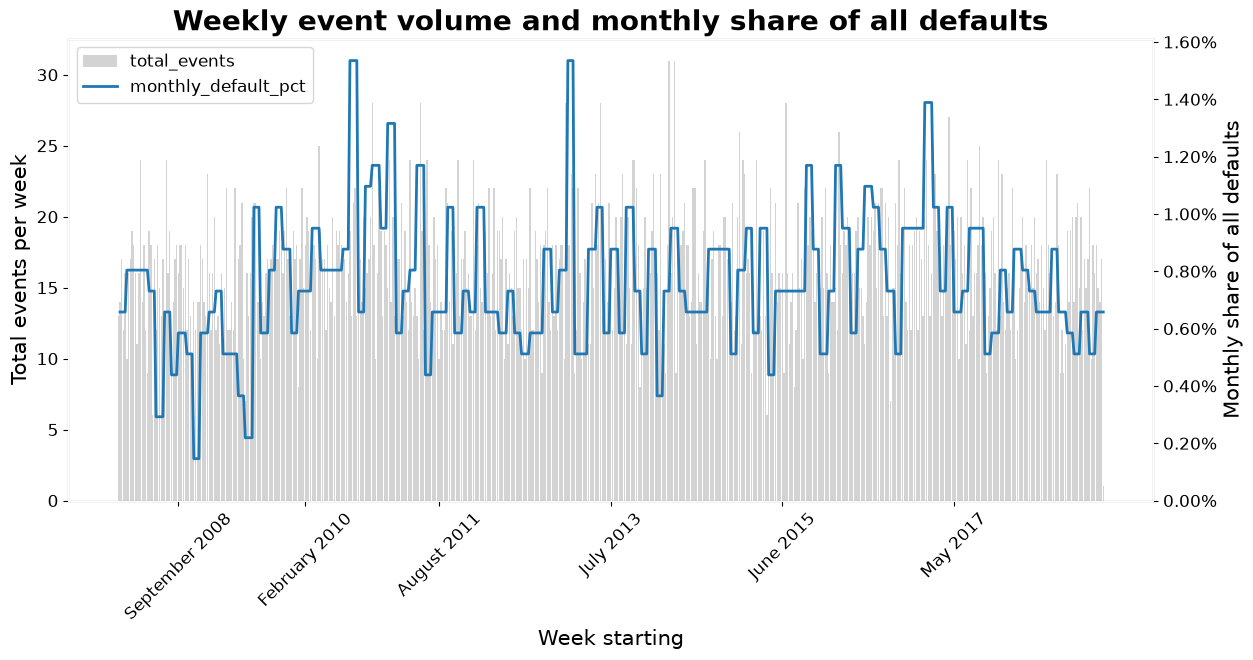

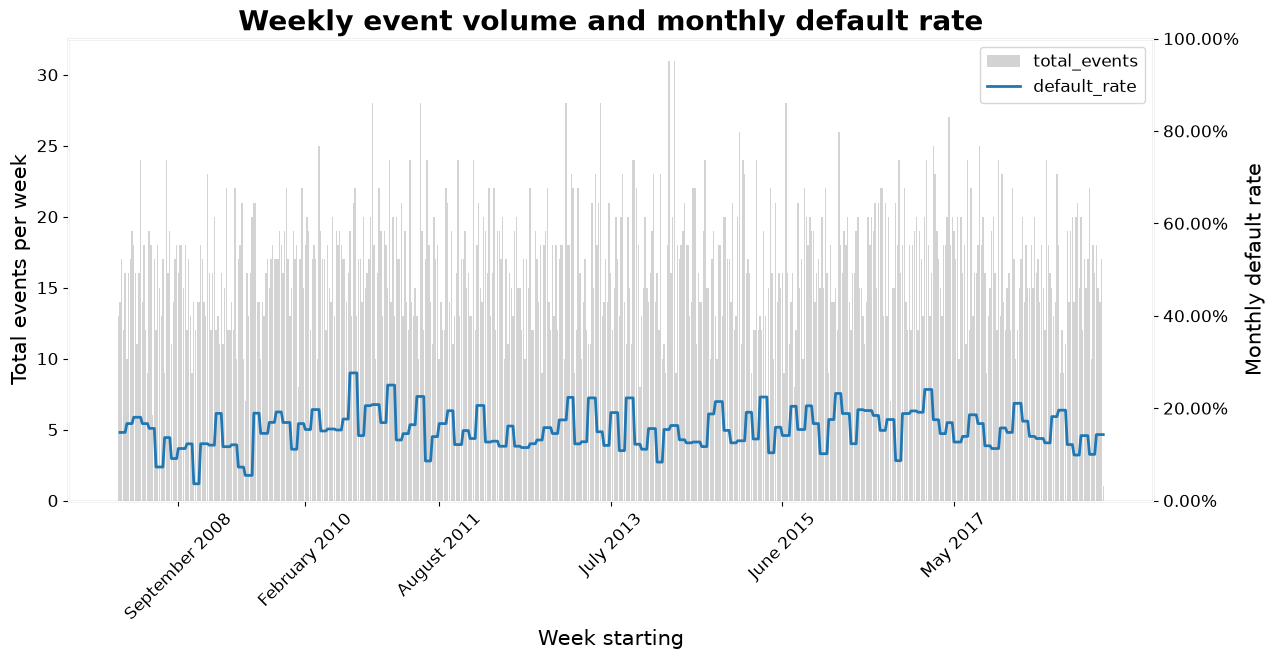

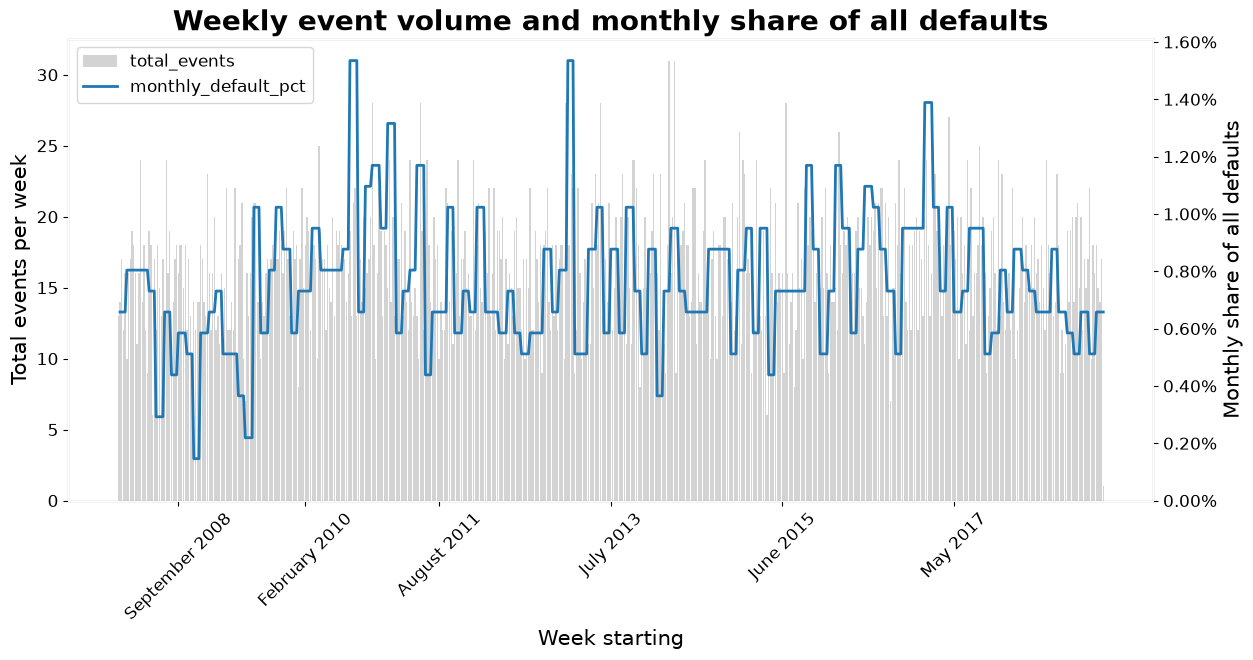

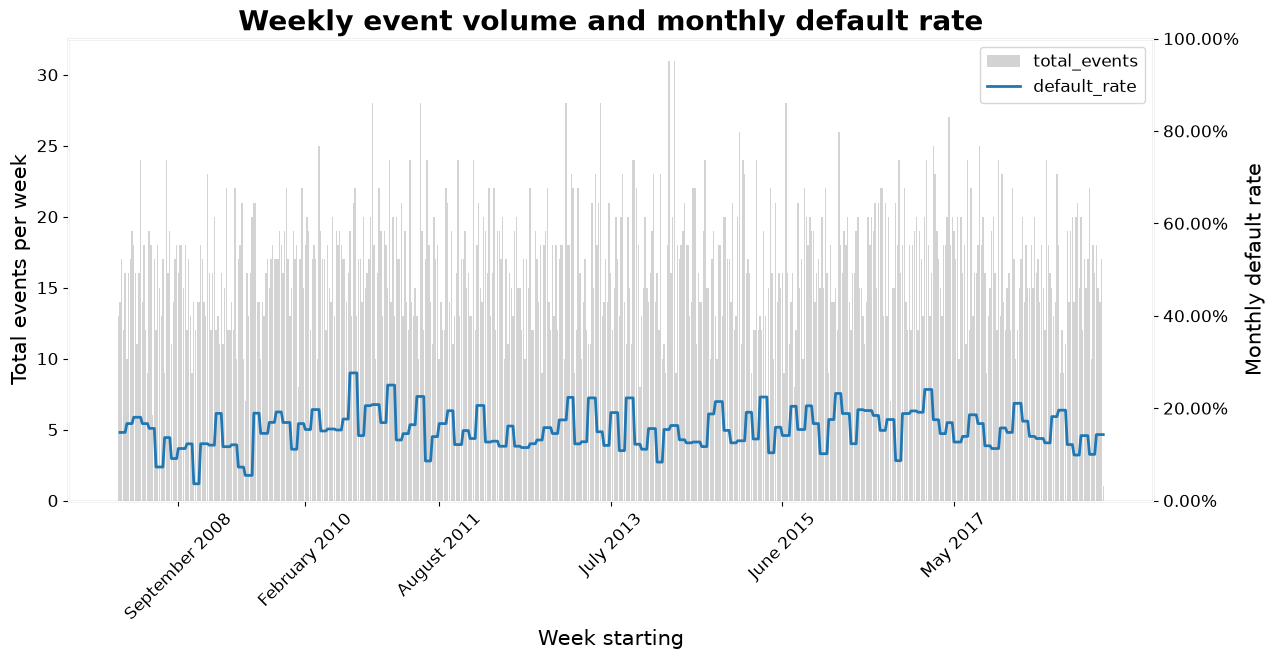

In [24]:
weekly_events = (
    dated_data.set_index("OBS_DATE")
    .resample("W-MON", label="left", closed="left")
    .size()
    .rename("total_events")
)
weekly_data = weekly_events.to_frame().reset_index().sort_values("OBS_DATE")
weekly_data["month"] = weekly_data["OBS_DATE"].dt.to_period("M")
monthly_metrics = monthly_data[
    ["OBS_DATE", "default_rate", "monthly_default_pct"]
].copy()
monthly_metrics["month"] = monthly_metrics["OBS_DATE"].dt.to_period("M")
monthly_metrics = monthly_metrics.drop(columns="OBS_DATE")
weekly_data = weekly_data.merge(
    monthly_metrics, on="month", how="left", sort=False
).drop(columns="month")

weekly_volume_default_share = plot_secondary(
    weekly_data,
    figsize=(14, 6),
    x_data="OBS_DATE",
    y1_data="total_events",
    y2_data="monthly_default_pct",
    x_label="Week starting",
    y1_label="Total events per week",
    y2_label="Monthly share of all defaults",
    title="Weekly event volume and monthly share of all defaults",
    rotation=45,
    y1_lim=None,
    y2_lim=None,
)
weekly_volume_default_rate = plot_secondary(
    weekly_data,
    figsize=(14, 6),
    x_data="OBS_DATE",
    y1_data="total_events",
    y2_data="default_rate",
    x_label="Week starting",
    y1_label="Total events per week",
    y2_label="Monthly default rate",
    title="Weekly event volume and monthly default rate",
    rotation=45,
    y1_lim=None,
    y2_lim=1,
)

display(weekly_volume_default_share)
display(weekly_volume_default_rate)

# Nulls/Errors Correlations

nulls in data and wrong types

In [25]:
target = labelled_df["target_var"]

In [26]:
features = labelled_df.drop(columns="target_var")

null_corr = features.isna().corrwith(target)

In [27]:
failed_masks = {}

for column, parser in parsers.items():
    values = labelled_df[column]
    parsed = parser(values, errors="coerce")

    failed = values.notna() & parsed.isna()
    failed_masks[column] = failed

In [28]:
wrong_type_corr = (
    pd.DataFrame(failed_masks)
    .corrwith(target)
)

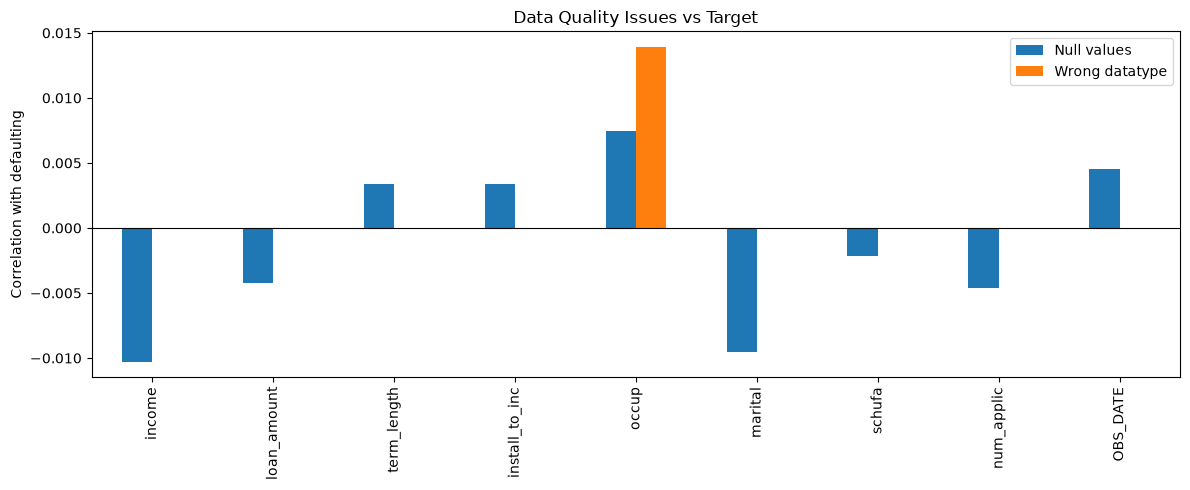

In [29]:
correlations = pd.DataFrame({
    "Null values": null_corr,
    "Wrong datatype": wrong_type_corr
}).fillna(0)

ax = correlations.plot.bar(figsize=(12, 5))

ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Correlation with defaulting")
ax.set_title("Data Quality Issues vs Target")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [30]:
from scipy.stats import chi2_contingency

indicators = features.isna()
indicators["occup_wrong_type"] = failed_masks["occup"]

results = {}

for column in indicators:
    table = pd.crosstab(indicators[column], target)

    if table.shape == (2, 2):
        _, p_value, _, _ = chi2_contingency(table)
        results[column] = p_value

pd.Series(results).sort_values()

occup_wrong_type    0.205784
income              0.347900
marital             0.387463
occup               0.504795
num_applic          0.695350
OBS_DATE            0.705828
loan_amount         0.722054
term_length         0.787199
install_to_inc      0.787199
schufa              0.879093
dtype: float64

In [31]:
from statsmodels.stats.multitest import multipletests

p_values = pd.Series(results)
adjusted = multipletests(p_values, method="fdr_bh")[1]

significance = pd.DataFrame({
    "p_value": p_values,
    "adjusted_p": adjusted
})

In [32]:
significance

,p_value,adjusted_p
income,0.347900,0.874665
loan_amount,0.722054,0.874665
term_length,0.787199,0.874665
install_to_inc,0.787199,0.874665
occup,0.504795,0.874665
marital,0.387463,0.874665
schufa,0.879093,0.879093
num_applic,0.695350,0.874665
OBS_DATE,0.705828,0.874665
occup_wrong_type,0.205784,0.874665


In [33]:
occup_issue = (
    labelled_df["occup"].isna()
    | failed_masks["occup"]
)

occup_issue_corr = occup_issue.astype(int).corr(target)

print("Correlation:", occup_issue_corr)

Correlation: 0.014418964275101786


In [34]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(table)

print("p-value:", p_value)
print("Minimum expected count:", expected.min())

p-value: 0.20578423704864823
Minimum expected count: 41.14222128020348


In [35]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

occup = labelled_df["occup"].astype("string").str.strip()
target = pd.to_numeric(labelled_df["target_var"], errors="coerce")

results = []

for value in ["1", "2", "3"]:
    flag = occup.eq(value).fillna(False)

    table = pd.crosstab(flag, target).reindex(
        index=[False, True],
        columns=[0, 1],
        fill_value=0
    )

    odds_ratio, p_value = fisher_exact(table)

    results.append({
        "occup_value": value,
        "count": flag.sum(),
        "default_count": ((flag) & target.eq(1)).sum(),
        "default_rate": target[flag].mean() * 100,
        "odds_ratio": odds_ratio,
        "p_value": p_value
    })

occup_results = pd.DataFrame(results)
occup_results

,occup_value,count,default_count,default_rate,odds_ratio,p_value
0,1,96,16,16.666667,1.099026,0.671975
1,2,90,11,12.222222,0.762590,0.465191
2,3,81,22,27.160494,2.063086,0.007637


verdict: null values don't add significant prediction impact. Errors do have stronger correlations (specifically occup = 3), but not in a practical sense (too few events)

Result: change errors to nulls, save separate columns for numerical occup for future model performance evaluation (with and without)

# Restoring income/loan_amount/term_length/install_to_inc (where possible)

In [36]:
def restore_financial_nulls(df):
    df = df.copy()
    
    columns = [
        "income",
        "loan_amount",
        "term_length",
        "install_to_inc"
    ]
    
    df[columns] = df[columns].apply(
        pd.to_numeric,
        errors="coerce"
    )
    
    # One equation can only solve one missing value
    one_missing = df[columns].isna().sum(axis=1).eq(1)
    
    income_missing = (
        one_missing
        & df["income"].isna()
        & df["loan_amount"].gt(0)
        & df["term_length"].gt(0)
        & df["install_to_inc"].gt(0)
    )
    
    loan_missing = (
        one_missing
        & df["loan_amount"].isna()
        & df["income"].gt(0)
        & df["term_length"].gt(0)
        & df["install_to_inc"].gt(0)
    )
    
    term_missing = (
        one_missing
        & df["term_length"].isna()
        & df["income"].gt(0)
        & df["loan_amount"].gt(0)
        & df["install_to_inc"].gt(0)
    )
    
    ratio_missing = (
        one_missing
        & df["install_to_inc"].isna()
        & df["income"].gt(0)
        & df["loan_amount"].gt(0)
        & df["term_length"].gt(0)
    )
    
    df.loc[income_missing, "income"] = (
        df.loc[income_missing, "loan_amount"]
        / df.loc[income_missing, "term_length"]
        / df.loc[income_missing, "install_to_inc"]
    )
    
    df.loc[loan_missing, "loan_amount"] = (
        df.loc[loan_missing, "income"]
        * df.loc[loan_missing, "install_to_inc"]
        * df.loc[loan_missing, "term_length"]
    )
    
    df.loc[term_missing, "term_length"] = (
        df.loc[term_missing, "loan_amount"]
        / (
            df.loc[term_missing, "income"]
            * df.loc[term_missing, "install_to_inc"]
        )
    ).round()  # Whole months
    
    df.loc[ratio_missing, "install_to_inc"] = (
        df.loc[ratio_missing, "loan_amount"]
        / df.loc[ratio_missing, "term_length"]
        / df.loc[ratio_missing, "income"]
    )
    
    filled_counts = pd.Series({
        "income": income_missing.sum(),
        "loan_amount": loan_missing.sum(),
        "term_length": term_missing.sum(),
        "install_to_inc": ratio_missing.sum()
    }, name="values_restored")
    return df, filled_counts


In [37]:
linked_cols = [
    "income",
    "loan_amount",
    "term_length",
    "install_to_inc"
]

labelled_before_restore = labelled_df.copy()

labelled_df, filled_counts = restore_financial_nulls(labelled_df)

labelled_after_restore = labelled_df.copy()

In [38]:
# Counts after algebraic restoration, but before removing null dates
rows_before_date_filter = len(labelled_before_restore)

nulls_after_restoration = (
    labelled_df[feature_cols].isna().sum()
)

restored_by_column = filled_counts.reindex(
    feature_cols,
    fill_value=0
)

nulls_before_restoration = (
    nulls_after_restoration + restored_by_column
)

# Remove rows without a valid observation date
labelled_df = (
    labelled_df.loc[labelled_df["OBS_DATE"].notna()]
    .reset_index(drop=True)
    .copy()
)

nulls_after_date_filter = (
    labelled_df[feature_cols].isna().sum()
)

null_comparison = pd.DataFrame({
    "nulls_before_restoration": nulls_before_restoration,
    "values_restored": restored_by_column,
    "nulls_after_restoration": nulls_after_restoration,
    "nulls_after_date_filter": nulls_after_date_filter
})

null_comparison["pct_before_restoration"] = (
    null_comparison["nulls_before_restoration"]
    / rows_before_date_filter
    * 100
)

null_comparison["pct_after_restoration"] = (
    null_comparison["nulls_after_restoration"]
    / rows_before_date_filter
    * 100
)

null_comparison["pct_after_date_filter"] = (
    null_comparison["nulls_after_date_filter"]
    / len(labelled_df)
    * 100
)

null_comparison

,nulls_before_restoration,values_restored,nulls_after_restoration,nulls_after_date_filter,pct_before_restoration,pct_after_restoration,pct_after_date_filter
income,587,494,93,87,6.220856,0.985587,0.977418
loan_amount,594,486,108,101,6.295040,1.144553,1.134704
term_length,547,462,85,82,5.796948,0.900805,0.921245
install_to_inc,547,449,98,88,5.796948,1.038576,0.988653
occup,558,0,558,530,5.913523,5.913523,5.954387
marital,576,0,576,551,6.104281,6.104281,6.190316
schufa,550,0,550,519,5.828741,5.828741,5.830806
num_applic,563,0,563,530,5.966511,5.966511,5.954387


In [39]:
def monthly_null_rates(df, columns):
    plot_data = df[["OBS_DATE"] + columns].copy()

    plot_data["OBS_DATE"] = pd.to_datetime(
        plot_data["OBS_DATE"],
        errors="coerce"
    )

    # Rows without dates cannot be assigned to a month
    plot_data = plot_data.dropna(subset=["OBS_DATE"])
    plot_data = plot_data.set_index("OBS_DATE")

    monthly_events = plot_data.resample("MS").size()

    monthly_null_cells = (
        plot_data[columns]
        .isna()
        .resample("MS")
        .sum()
        .sum(axis=1)
    )

    monthly = pd.DataFrame({
        "total_events": monthly_events,
        "null_cells": monthly_null_cells
    })

    monthly = monthly.loc[
        monthly["total_events"].gt(0)
    ].copy()

    monthly["possible_cells"] = (
        monthly["total_events"] * len(columns)
    )

    monthly["null_rate"] = (
        monthly["null_cells"]
        / monthly["possible_cells"]
    )

    return monthly.reset_index()

In [40]:
monthly_before = monthly_null_rates(
    labelled_before_restore,
    linked_cols
)

monthly_after = monthly_null_rates(
    labelled_after_restore,
    linked_cols
)

shared_y_limit = max(
    monthly_before["null_rate"].max(),
    monthly_after["null_rate"].max()
) * 1.1

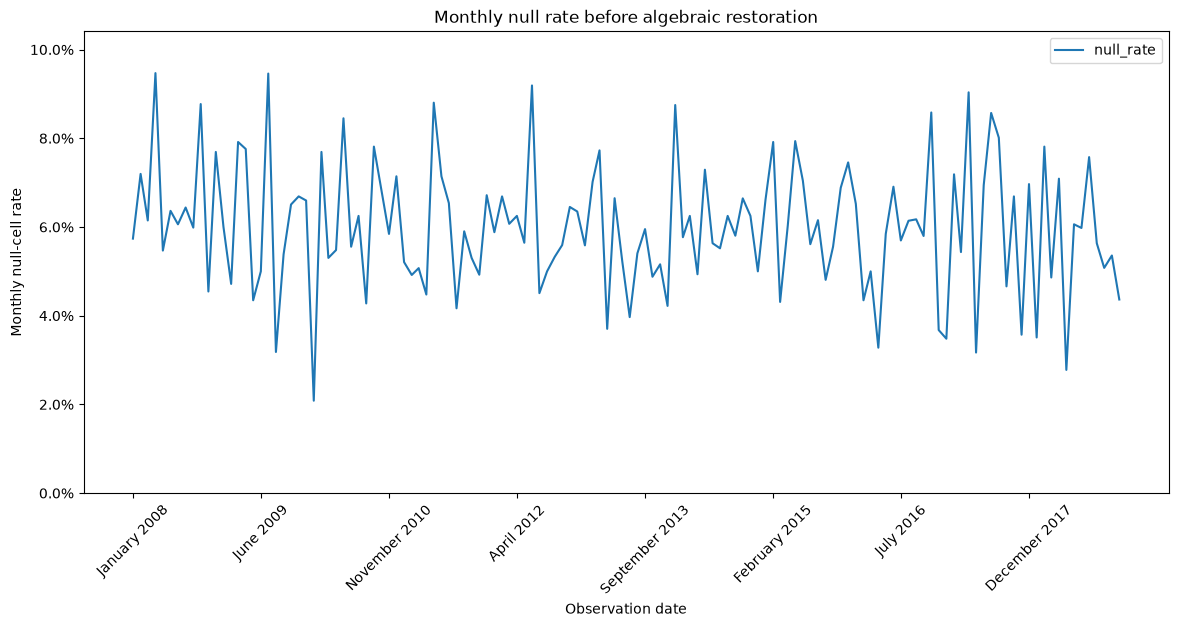

In [41]:
figure_before = plot_single(
    monthly_before,
    figsize=(14, 6),
    x_data="OBS_DATE",
    y_data="null_rate",
    x_label="Observation date",
    y_label="Monthly null-cell rate",
    title="Monthly null rate before algebraic restoration",
    rotation=45,
    plot_type="line",
    y_lim=shared_y_limit
)

plt.show()

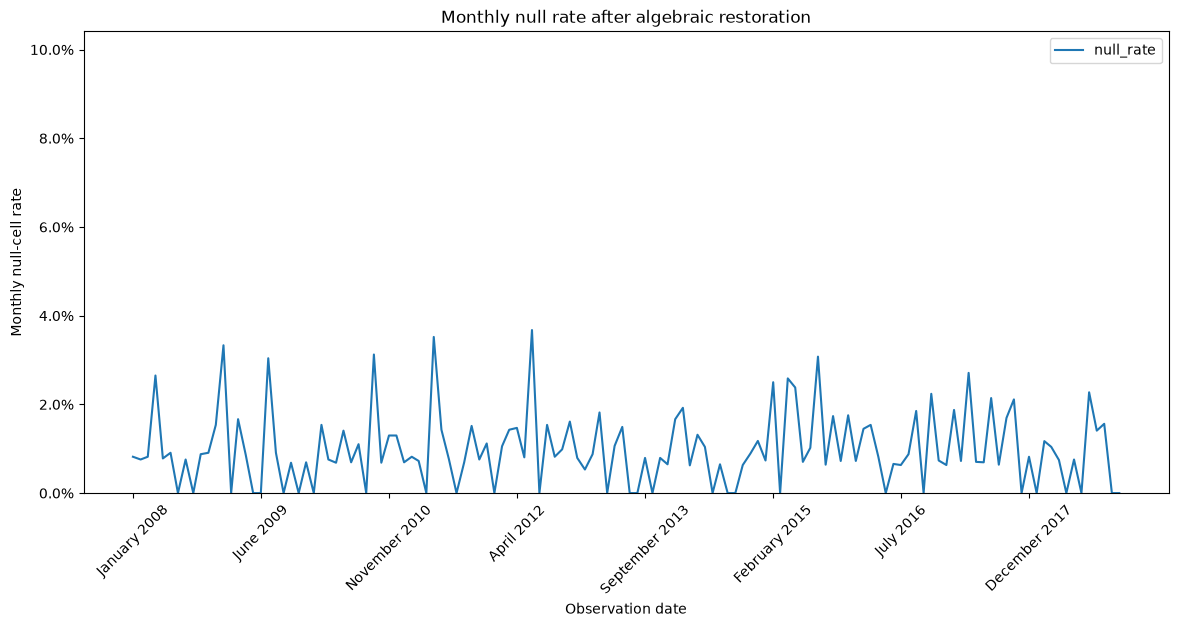

In [42]:
figure_after = plot_single(
    monthly_after,
    figsize=(14, 6),
    x_data="OBS_DATE",
    y_data="null_rate",
    x_label="Observation date",
    y_label="Monthly null-cell rate",
    title="Monthly null rate after algebraic restoration",
    rotation=45,
    plot_type="line",
    y_lim=shared_y_limit
)

plt.show()

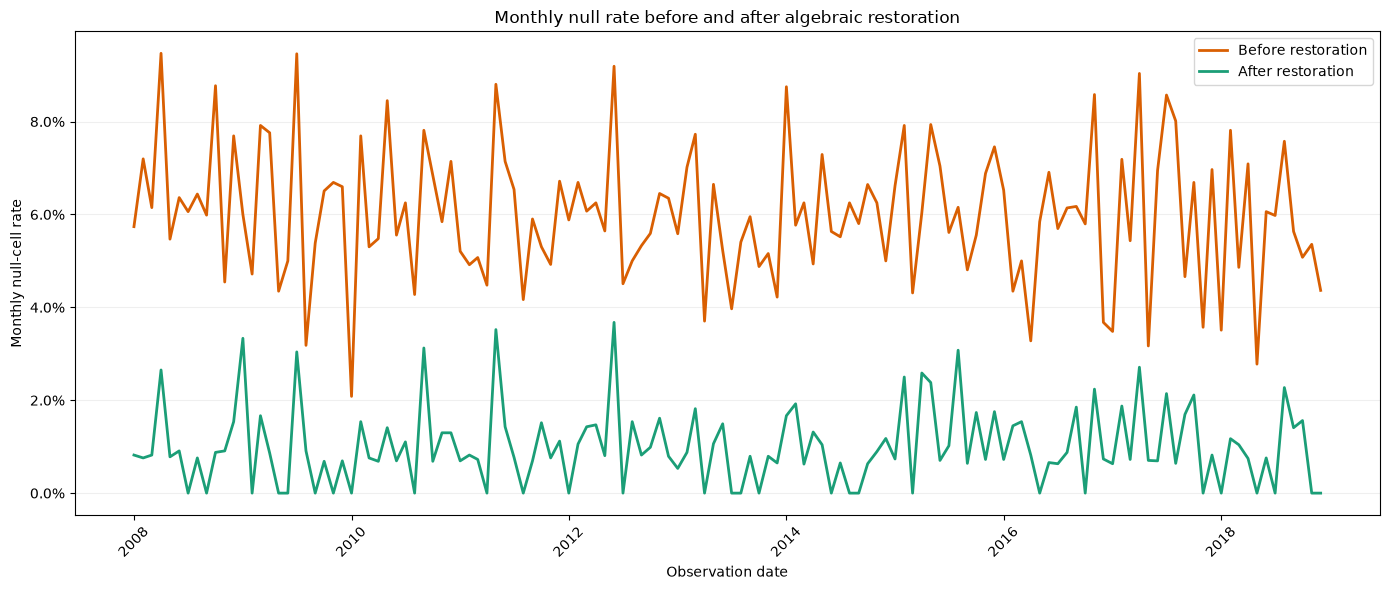

In [43]:
monthly_comparison = (
    monthly_before[["OBS_DATE", "null_rate"]]
    .rename(columns={"null_rate": "before_restoration"})
    .merge(
        monthly_after[["OBS_DATE", "null_rate"]]
        .rename(columns={"null_rate": "after_restoration"}),
        on="OBS_DATE",
        how="outer"
    )
    .sort_values("OBS_DATE")
)

from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    monthly_comparison["OBS_DATE"],
    monthly_comparison["before_restoration"],
    label="Before restoration",
    color="#D95F02",
    linewidth=2
)

ax.plot(
    monthly_comparison["OBS_DATE"],
    monthly_comparison["after_restoration"],
    label="After restoration",
    color="#1B9E77",
    linewidth=2
)

ax.set(
    title="Monthly null rate before and after algebraic restoration",
    xlabel="Observation date",
    ylabel="Monthly null-cell rate"
)

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

# Categorical features encoding and error fixes

### Substituting errors with nulls

In [44]:
occup_raw = labelled_df["occup"].astype("string").str.strip()

for code in ["1", "2", "3"]:
    labelled_df[f"occup_code_{code}"] = (
        occup_raw.eq(code)
        .fillna(False)
        .astype("int8")
    )

# Replace the original numeric values with null
numeric_occup = occup_raw.isin(["1", "2", "3"])
labelled_df.loc[numeric_occup, "occup"] = pd.NA

In [45]:
categorical_cols = ["occup", "marital", "num_applic"]
labelled_df = pd.get_dummies(
    labelled_df,
    columns=categorical_cols,
    dummy_na=True,
    dtype="int8"
)
labelled_df.columns

Index(['income', 'loan_amount', 'term_length', 'install_to_inc', 'schufa',
       'OBS_DATE', 'target_var', 'occup_code_1', 'occup_code_2',
       'occup_code_3', 'occup_Employee', 'occup_Student', 'occup_Worker',
       'occup_nan', 'marital_Divorced', 'marital_Living together',
       'marital_Married', 'marital_Separated', 'marital_Single', 'marital_nan',
       'num_applic_1', 'num_applic_2', 'num_applic_nan'],
      dtype='str')

# SCHUFA "Current Performance"

Rows evaluated: 8,382
Coverage: 94.17%
ROC-AUC: 0.789


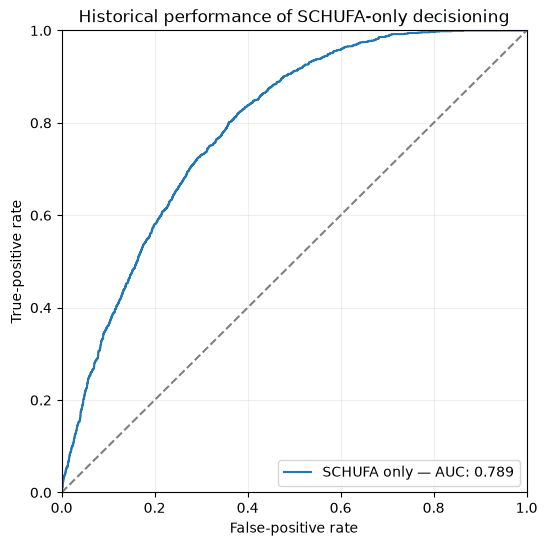

In [46]:
evaluation_df = labelled_df

schufa = pd.to_numeric(evaluation_df["schufa"], errors="coerce")
target = evaluation_df["target_var"]

valid = schufa.notna() & target.isin([0, 1])

y_true = target.loc[valid].astype(int)

# Use the minus sign if higher SCHUFA means lower default risk
y_score = -schufa.loc[valid]

fpr, tpr, thresholds = roc_curve(y_true, y_score)
auc = roc_auc_score(y_true, y_score)

print(f"Rows evaluated: {valid.sum():,}")
print(f"Coverage: {valid.mean():.2%}")
print(f"ROC-AUC: {auc:.3f}")

fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(fpr, tpr, label=f"SCHUFA only — AUC: {auc:.3f}")
ax.plot([0, 1], [0, 1], "--", color="grey")

ax.set(
    title="Historical performance of SCHUFA-only decisioning",
    xlabel="False-positive rate",
    ylabel="True-positive rate",
    xlim=(0, 1),
    ylim=(0, 1)
)

ax.legend()
ax.grid(alpha=0.2)
plt.show()

In [47]:
auc_original = roc_auc_score(y_true, schufa.loc[valid])
auc_inverted = roc_auc_score(y_true, -schufa.loc[valid])

print("Original AUC:", auc_original)
print("Inverted AUC:", auc_inverted)

Original AUC: 0.21051146801675344
Inverted AUC: 0.7894885319832465


# Train/Test Split

In [48]:
len(labelled_df)

8901

In [49]:
import pandas as pd

split_data = labelled_df[["OBS_DATE", "target_var"]].copy()

split_data = (
    split_data[
        split_data["OBS_DATE"].notna()
        & split_data["target_var"].isin([0, 1])
    ]
    .sort_values("OBS_DATE")
    .reset_index(drop=True)
)

total_rows = len(split_data)

candidate_dates = []

for percentage in range(70, 81):
    position = int(total_rows * percentage / 100) - 1
    candidate_dates.append(split_data.loc[position, "OBS_DATE"])

candidate_dates = pd.Series(candidate_dates).drop_duplicates()
results = []

for cutoff in candidate_dates:
    train = split_data["OBS_DATE"] <= cutoff
    test = ~train

    train_total = train.sum()
    test_total = test.sum()
    train_defaults = (train & split_data["target_var"].eq(1)).sum()
    test_defaults = (test & split_data["target_var"].eq(1)).sum()
    train_non_defaults = (train & split_data["target_var"].eq(0)).sum()
    test_non_defaults = (test & split_data["target_var"].eq(0)).sum()
    train_default_rate = train_defaults / train_total
    test_default_rate = test_defaults / test_total

    results.append({
        "cutoff_date": cutoff,
        "train_test_split": (
        f"{train_total / total_rows:.1%}"
    ),
        "train_defaults": train_defaults,
        "train_default_rate": train_default_rate,
        "train_non_defaults": train_non_defaults,
        "train_non_default_rate": train_non_defaults / train_total,
        "test_defaults": test_defaults,
        "test_default_rate": test_default_rate,
        "test_non_defaults": test_non_defaults,
        "test_non_default_rate": test_non_defaults / test_total,
        "default_rate_difference": (
            abs(test_default_rate - train_default_rate)
        )
    })

candidate_stats = pd.DataFrame(results)

candidate_stats

,cutoff_date,train_test_split,train_defaults,train_default_rate,train_non_defaults,train_non_default_rate,test_defaults,test_default_rate,test_non_defaults,test_non_default_rate,default_rate_difference
0,2015-10-02,70.0%,945,0.151685,5285,0.848315,423,0.158368,2248,0.841632,0.006682
1,2015-11-12,71.0%,960,0.151923,5359,0.848077,408,0.158017,2174,0.841983,0.006094
2,2015-12-25,72.0%,971,0.151529,5437,0.848471,397,0.159246,2096,0.840754,0.007717
3,2016-02-03,73.0%,991,0.152508,5507,0.847492,377,0.156887,2026,0.843113,0.004379
4,2016-03-16,74.0%,1009,0.153181,5578,0.846819,359,0.155143,1955,0.844857,0.001962
5,2016-04-22,75.0%,1020,0.152786,5656,0.847214,348,0.156404,1877,0.843596,0.003618
6,2016-06-01,76.0%,1038,0.153459,5726,0.846541,330,0.154422,1807,0.845578,0.000963
7,2016-07-08,77.0%,1054,0.153756,5801,0.846244,314,0.153470,1732,0.846530,0.000286
8,2016-08-11,78.0%,1067,0.153702,5875,0.846298,301,0.153650,1658,0.846350,0.000052
9,2016-09-22,79.0%,1079,0.153441,5953,0.846559,289,0.154628,1580,0.845372,0.001187


In [50]:
model_data = labelled_df.copy()

model_data = (
    model_data[
        model_data["OBS_DATE"].notna()
        & model_data["target_var"].isin([0, 1])
    ]
    .sort_values("OBS_DATE")
    .reset_index(drop=True)
)

chosen_cutoff = pd.Timestamp("2016-03-16")
test_start = chosen_cutoff + pd.Timedelta(days=1)

train_df = model_data.loc[
    model_data["OBS_DATE"] < test_start
].copy()

test_df = model_data.loc[
    model_data["OBS_DATE"] >= test_start
].copy()

In [51]:
split_summary = pd.DataFrame({
    "rows": [len(train_df), len(test_df)],
    "share": [
        len(train_df) / len(model_data),
        len(test_df) / len(model_data)
    ],
    "defaults": [
        train_df["target_var"].eq(1).sum(),
        test_df["target_var"].eq(1).sum()
    ],
    "default_rate": [
        train_df["target_var"].mean(),
        test_df["target_var"].mean()
    ],
    "date_from": [
        train_df["OBS_DATE"].min(),
        test_df["OBS_DATE"].min()
    ],
    "date_to": [
        train_df["OBS_DATE"].max(),
        test_df["OBS_DATE"].max()
    ]
}, index=["Train", "Test"])

display(
    split_summary.style.format({
        "share": "{:.1%}",
        "default_rate": "{:.2%}",
        "date_from": "{:%Y-%m-%d}",
        "date_to": "{:%Y-%m-%d}"
    })
)

,rows,share,defaults,default_rate,date_from,date_to
Train,6587,74.0%,1009,15.32%,2008-01-02,2016-03-16
Test,2314,26.0%,359,15.51%,2016-03-17,2018-12-31


In [52]:
data_path = Path("../data")
data_path.mkdir(parents=True, exist_ok=True)

train_path = data_path / "train.csv"
test_path = data_path / "test.csv"

train_df.to_csv(
    train_path,
    index=False,
    date_format="%Y-%m-%d"
)

test_df.to_csv(
    test_path,
    index=False,
    date_format="%Y-%m-%d"
)

print("Saved:", train_path.resolve())
print("Saved:", test_path.resolve())

Saved: /Users/valery/VS Code Repos/OliverWymanTakeHomeTask/data/train.csv
Saved: /Users/valery/VS Code Repos/OliverWymanTakeHomeTask/data/test.csv


# Visuals

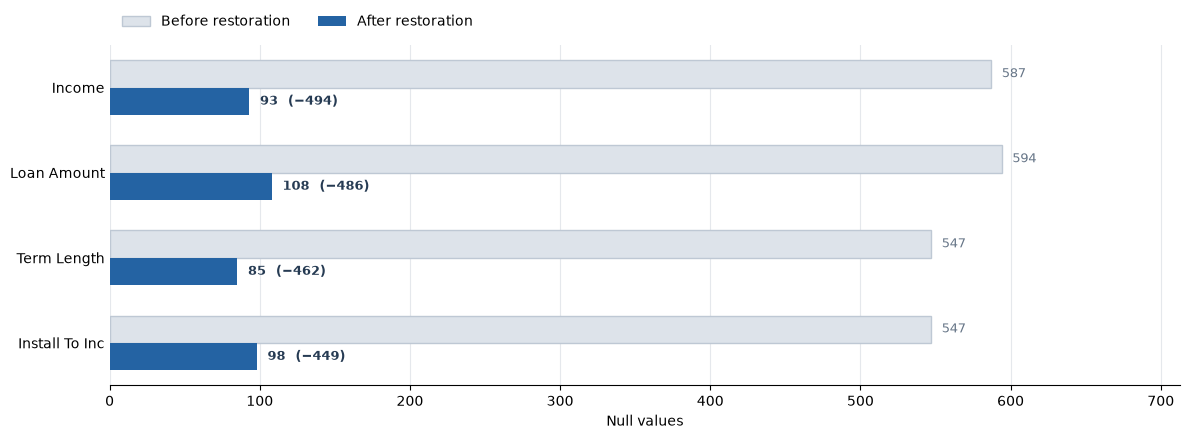

In [56]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

feature_order = [
    "income",
    "loan_amount",
    "term_length",
    "install_to_inc"
]

plot_data = null_comparison.loc[
    feature_order,
    [
        "nulls_before_restoration",
        "nulls_after_restoration",
        "values_restored"
    ]
].copy()

labels = [
    feature.replace("_", " ").title()
    for feature in plot_data.index
]

y = np.arange(len(plot_data))
bar_height = 0.32

before_colour = "#DDE3EA"
after_colour = "#2463A3"
text_colour = "#263B53"

fig, ax = plt.subplots(figsize=(12, 4.5))

ax.barh(
    y - bar_height / 2,
    plot_data["nulls_before_restoration"],
    height=bar_height,
    color=before_colour,
    edgecolor="#BEC8D4",
    label="Before restoration"
)

ax.barh(
    y + bar_height / 2,
    plot_data["nulls_after_restoration"],
    height=bar_height,
    color=after_colour,
    label="After restoration"
)

label_offset = (
    plot_data["nulls_before_restoration"].max() * 0.012
)

for index, (_, row) in enumerate(plot_data.iterrows()):
    before = int(row["nulls_before_restoration"])
    after = int(row["nulls_after_restoration"])
    restored = int(row["values_restored"])

    ax.text(
        before + label_offset,
        index - bar_height / 2,
        f"{before:,}",
        va="center",
        fontsize=9,
        color="#667587"
    )

    after_label = (
        f"{after:,}  (−{restored:,})"
        if restored > 0
        else f"{after:,}"
    )

    ax.text(
        after + label_offset,
        index + bar_height / 2,
        after_label,
        va="center",
        fontsize=9,
        fontweight="bold",
        color=text_colour
    )

ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.invert_yaxis()

ax.set_xlabel("Null values")
ax.xaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

ax.xaxis.grid(
    True,
    color="#E5E8EC",
    linewidth=0.8
)
ax.set_axisbelow(True)

ax.set_xlim(
    0,
    plot_data["nulls_before_restoration"].max() * 1.2
)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0)

ax.legend(
    frameon=False,
    loc="lower left",
    bbox_to_anchor=(0, 1.01),
    ncol=2,
    columnspacing=2
)

plt.tight_layout()

fig.savefig(
    "algebraic_restoration.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()